# heatwaves_Hobday2016_obs.ipynb
## Calculate marine heatwaves with Observations using the method outlined in Hobday et al. 2016

#### Created by Brendan Myers
##### 09/02/2026

In [1]:
%matplotlib inline
# import warnings
# warnings.filterwarnings('ignore')
import os
from glob import glob
from collections import OrderedDict
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs

import pandas as pd

import xesmf #for regridding
xr.set_options(keep_attrs=True)
import regionmask #for generating 1° ocean mask
# import m6toolbox

import xmhw

ERROR 1: PROJ: proj_create_from_database: Open of /glade/work/brendanmy/conda-envs/bgc-env/share/proj failed


### Make a standard 1° ones masks for masking, etc. (one for lons -180 to 180 and one for lons 0 to 360)

In [2]:
ones2 = np.full((180,360),1,dtype=int)
ones2 = xr.DataArray(ones2,dims=('lat','lon'))
ones2['lat'] = np.arange(-89.5, 90, 1)
ones2['lon'] = np.arange(0.5, 360, 1)

### Read in the standard 1° basin mask

In [3]:
# Define the 1-degree latitude and longitude points
lon = np.arange(-179.5, 180, 1)
lat = np.arange(-89.5, 90, 1)

# Create the land mask using Natural Earth data (default resolution is 1:110m)
# The mask will be boolean (True for land) on the specified grid
land_mask = regionmask.defined_regions.natural_earth_v5_1_2.land_110.mask(lon, lat)
land_mask = land_mask.where(land_mask==0, other=1)

In [4]:
ones = np.full((180,360),1,dtype=int)
ones = xr.DataArray(ones,dims=('lat','lon'))
ones['lat'] = np.arange(-89.5, 90, 1)
ones['lon'] = np.arange(-179.5, 180, 1)
ones = ones.where(land_mask == 1)

In [5]:
### forth, get the major basins mask, created using 'make_major_basins_mask.ipynb'
major_basins = xr.open_dataset('../tools/major_basins_1x1.nc')

major_basins = major_basins.basin.values
major_basins = xr.DataArray(major_basins, dims=('lat','lon'))

# Read in observational data monthly climatologies that have been regridded to 1°

In [6]:
file = '../tools/Obs4biomes.nc'
ds_obs = xr.open_dataset(file)

In [7]:
ds_obs

<xarray.Dataset> Size: 25MB
Dimensions:  (lat: 180, lon: 360, month: 12)
Coordinates:
  * lat      (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
  * month    (month) float64 96B 1.0 2.0 3.0 4.0 5.0 ... 8.0 9.0 10.0 11.0 12.0
Data variables:
    MLD      (lat, lon, month) float64 6MB ...
    Chl      (lat, lon, month) float64 6MB ...
    Ice      (lat, lon, month) float64 6MB ...
    SST      (lat, lon, month) float64 6MB ...

# A few precalculations....

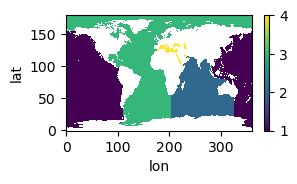

In [8]:
major_basins.plot(figsize=(3,1.5))

### Assign basins

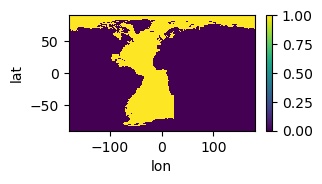

In [9]:
Atlantic = ones.where(major_basins == 3, other=0)
#.where(major_basins.basin == 3) #ones.where(ds_grid.REGION_MASK >= 5, other=0).where(ds_grid.REGION_MASK<10, other=0)
Atlantic.plot(figsize=(3,1.5))

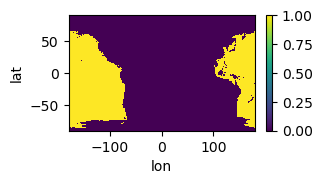

In [10]:
Pacific = ones.where(major_basins == 1, other=0)
Pacific.plot(figsize=(3,1.5))

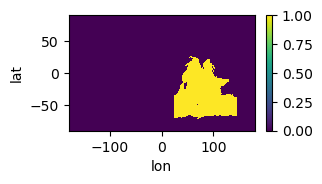

In [11]:
Indian = ones.where(major_basins == 2, other=0)
Indian.plot(figsize=(3,1.5))

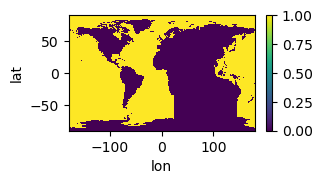

In [12]:
Atlantic_Pacific = Atlantic + Pacific
Atlantic_Pacific.plot(figsize=(3,1.5))

In [13]:
ds_obs['basin_mask'] = major_basins
ds_obs

<xarray.Dataset> Size: 25MB
Dimensions:     (lat: 180, lon: 360, month: 12)
Coordinates:
  * lat         (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 87.5 88.5 89.5
  * lon         (lon) float64 3kB -179.5 -178.5 -177.5 ... 177.5 178.5 179.5
  * month       (month) float64 96B 1.0 2.0 3.0 4.0 5.0 ... 9.0 10.0 11.0 12.0
Data variables:
    MLD         (lat, lon, month) float64 6MB ...
    Chl         (lat, lon, month) float64 6MB ...
    Ice         (lat, lon, month) float64 6MB ...
    SST         (lat, lon, month) float64 6MB ...
    basin_mask  (lat, lon) float64 518kB nan nan nan nan nan ... 3.0 3.0 3.0 3.0

In [18]:
ds_obs.SST.where(~np.isnan(ds_obs.SST), drop=True).values

array([[[        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        ...,
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan]],

       [[-0.20998751,         nan,         nan, ...,         nan,
                 nan, -0.23375086],
        [-0.15749232,         nan,         nan, ...,         nan,
                 nan, -1.17377369],
        [-0.63124759,         nan,         nan, ...,         nan,
                 nan, -1.02122146],
        ...,
        [-0.34624605,         nan,         nan, ...,  

In [ ]:
ds_obs['SST_anom'] = ds_obs['SST'] - ds_obs['SST']
ds_obs['SST_anom'].attrs = ds_obs['SST_anom'].attrs | {'long_name': 'Sea Surface Temperature Anomoly'}

KeyError: 'time'

# Calc Heatwaves

## Monthly

In [ ]:
# Need groupby to do this by month
quantile_upp = ds_obs.SST_anom.groupby('time.month').quantile(0.9, dim='time', skipna=True)
quantile_low = ds_obs.SST_anom.groupby('time.month').quantile(0.1, dim='time', skipna=True)
#annual too


tmp_g = ds_obs.groupby('time.month')

mon_sep_list_mhw = []
mon_sep_list_mcw = []
for mon in range(1,13):
    tmp = tmp_g[mon]
    mon_sep_list_mhw.append(tmp.SST_anom.where((tmp.SST_anom>=quantile_upp[mon-1]) | (ds_obs.SST_anom.isnull()), other=-9999).drop_vars(['month']))
    mon_sep_list_mcw.append(tmp.SST_anom.where((tmp.SST_anom<=quantile_low[mon-1]) | (ds_obs.SST_anom.isnull()), other=-9999).drop_vars(['month']))

ds_obs['MHW'] = xr.concat(mon_sep_list_mhw, dim='time', coords='minimal').sortby('time').rename('MHW')
ds_obs['MHW'].attrs = ds_obs['MHW'].attrs | {'quantile': quantile_upp['quantile'].item()}
ds_obs['MCW'] = xr.concat(mon_sep_list_mcw, dim='time', coords='minimal').sortby('time').rename('MCW')
ds_obs['MCW'].attrs = ds_obs['MCW'].attrs | {'quantile': quantile_low['quantile'].item()}

ds_obs = ds_obs.drop_vars('quantile')

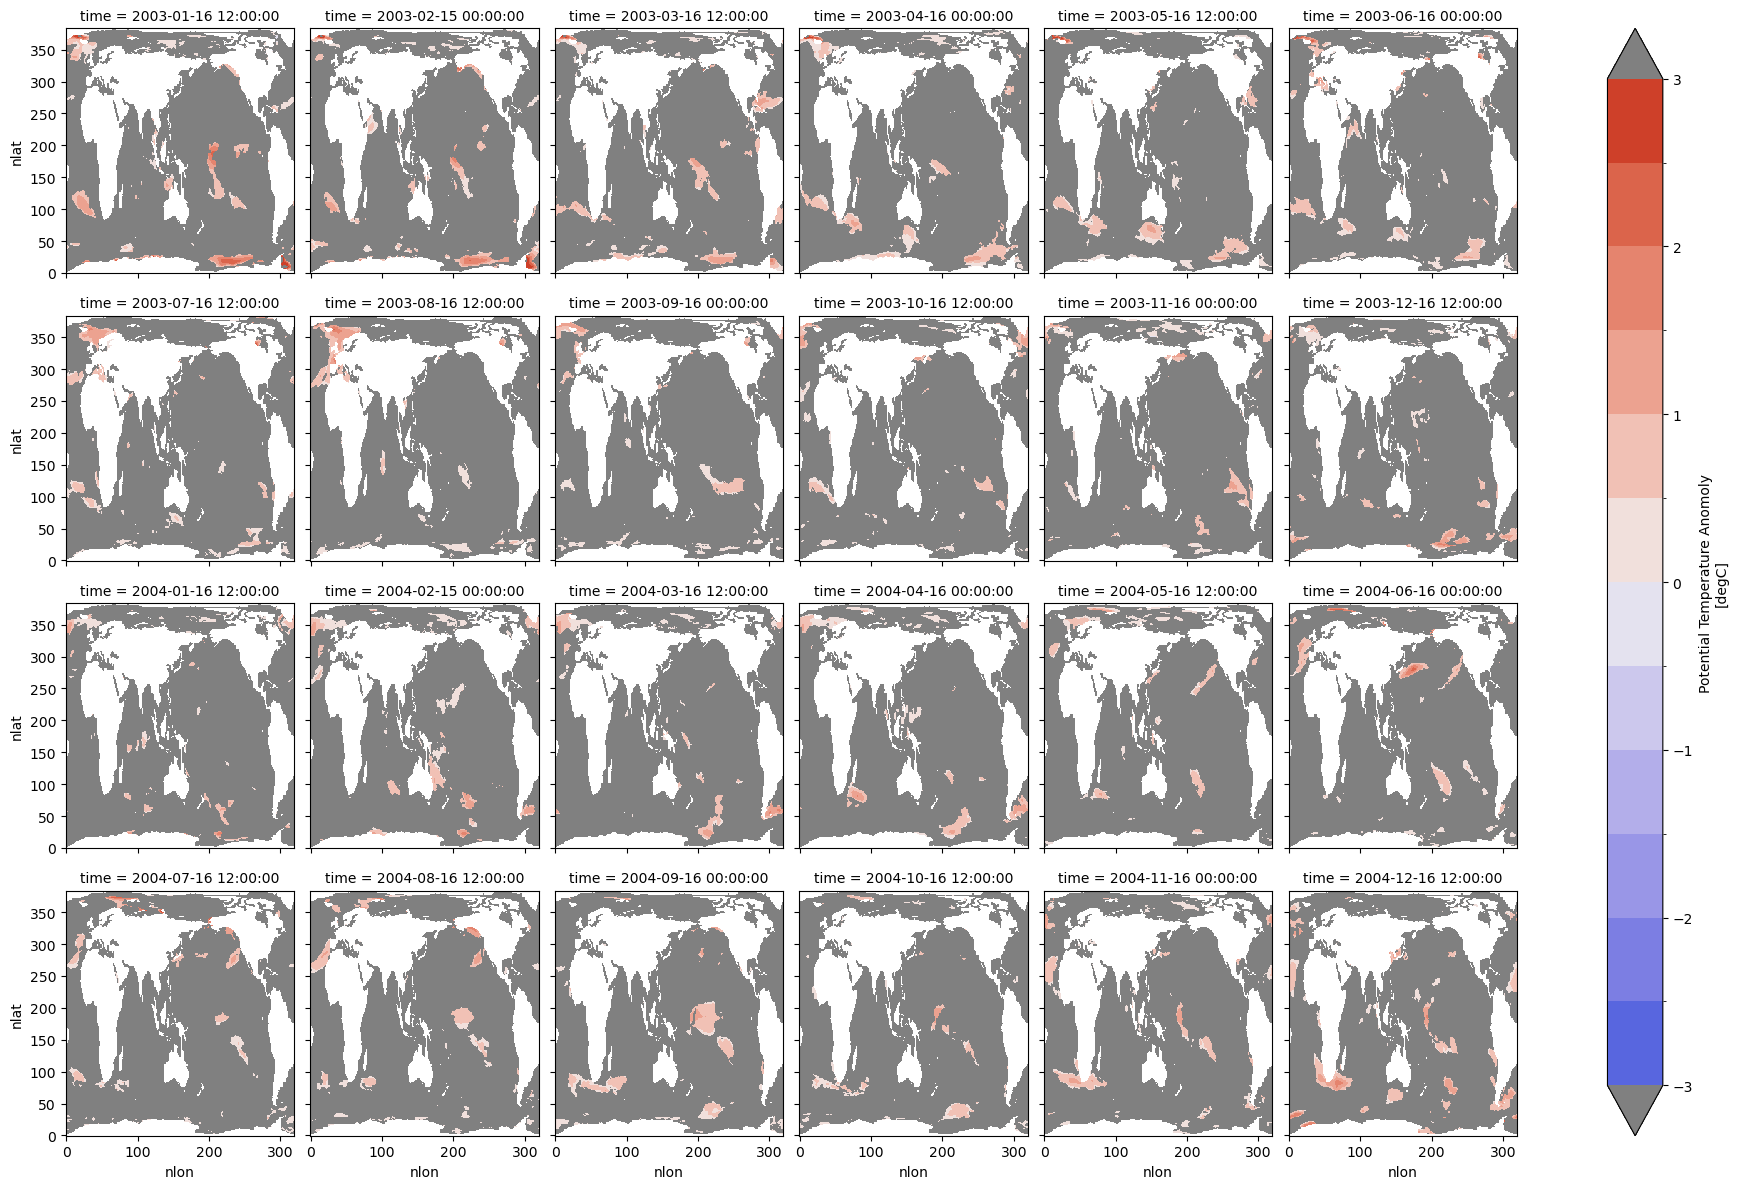

In [ ]:
# Marine Heatwaves at Timesteps

# cmap_hw = cc.cm.fire
# cmap_hw.set_over("magenta")  # Color for data above vmax
# cmap_hw.set_under("grey")

cmap_div = cc.cm.coolwarm
cmap_div.set_over("grey")  # Color for data above vmax
cmap_div.set_under("grey")

ds_obs.isel(time=slice(0,24)).MHW.plot(col='time', col_wrap=6, cmap=cmap_div, levels=np.arange(-3, 3.5, .5), cbar_kwargs={'extend':'both'})

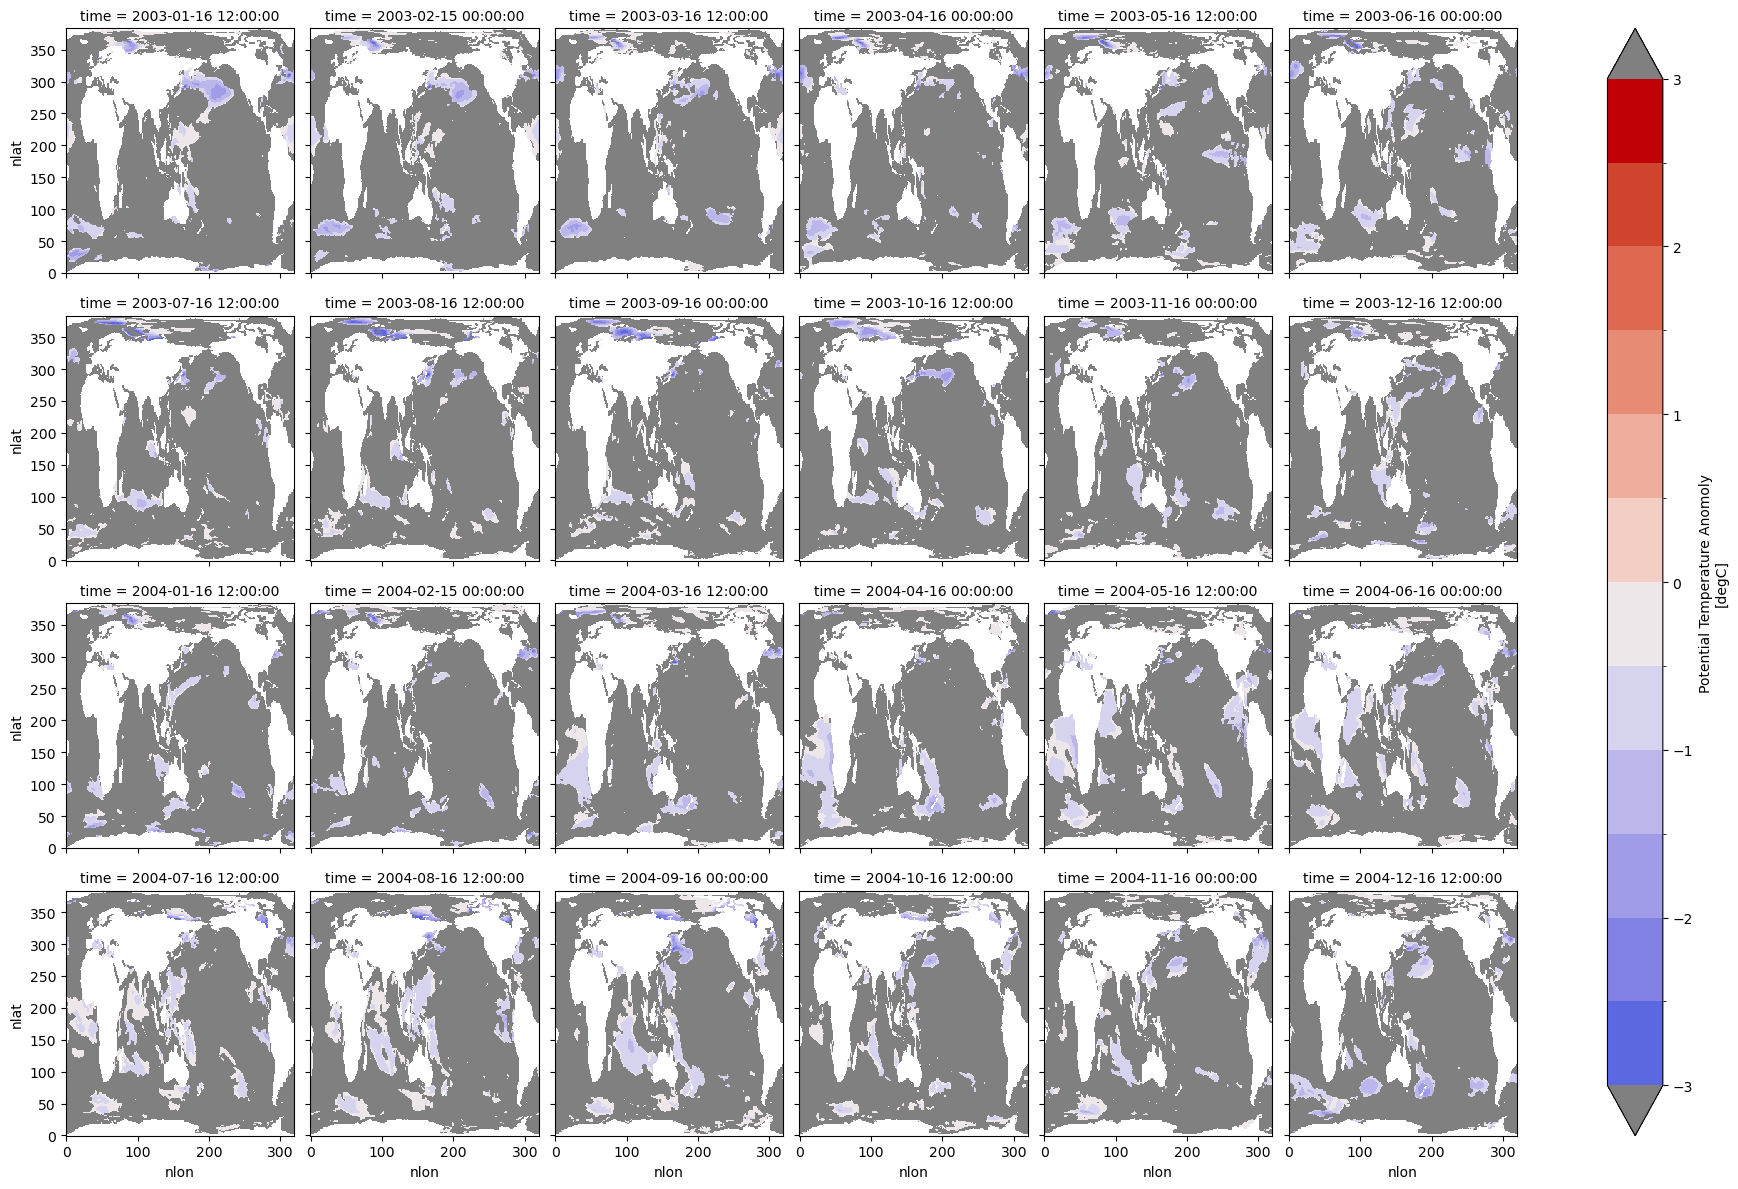

In [ ]:
# Marine Coldwaves at Timesteps

# cmap_hw = cc.cm.kbc_r
# cmap_hw.set_over("purple")  # Color for data above vmax
# cmap_hw.set_under("grey")

ds_obs.isel(time=slice(0,24)).MCW.plot(col='time', col_wrap=6, cmap=cmap_div, levels=np.arange(-3, 3.5, .5), cbar_kwargs={'extend':'both'})

In [ ]:
# Compute Intensity and Merge MHW and MCW together

ds_intensity = xr.merge([ds_obs.MHW.where(ds_obs.MHW>-999, drop=False).groupby('time.month').mean('time').rename('MHW_INTENSITY'),ds_obs.MCW.where(ds_obs.MCW>-999, drop=False).groupby('time.month').mean('time').rename('MCW_INTENSITY')])

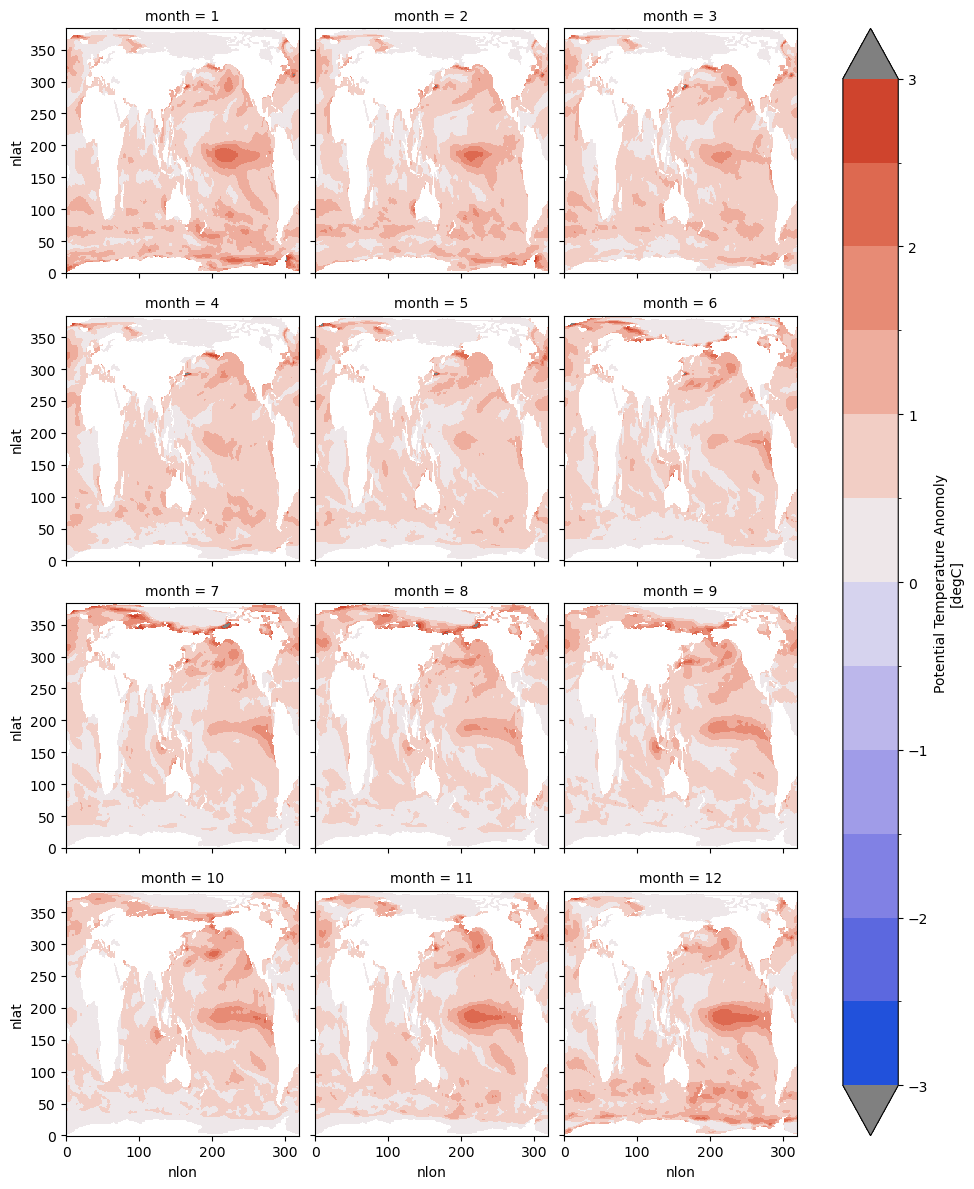

In [ ]:
# Intensity of Marine Heatwaves

ds_intensity['MHW_INTENSITY'].plot(col='month',col_wrap=3, cmap=cmap_div, levels=np.arange(-3, 3.5, .5), cbar_kwargs={'extend':'both'})

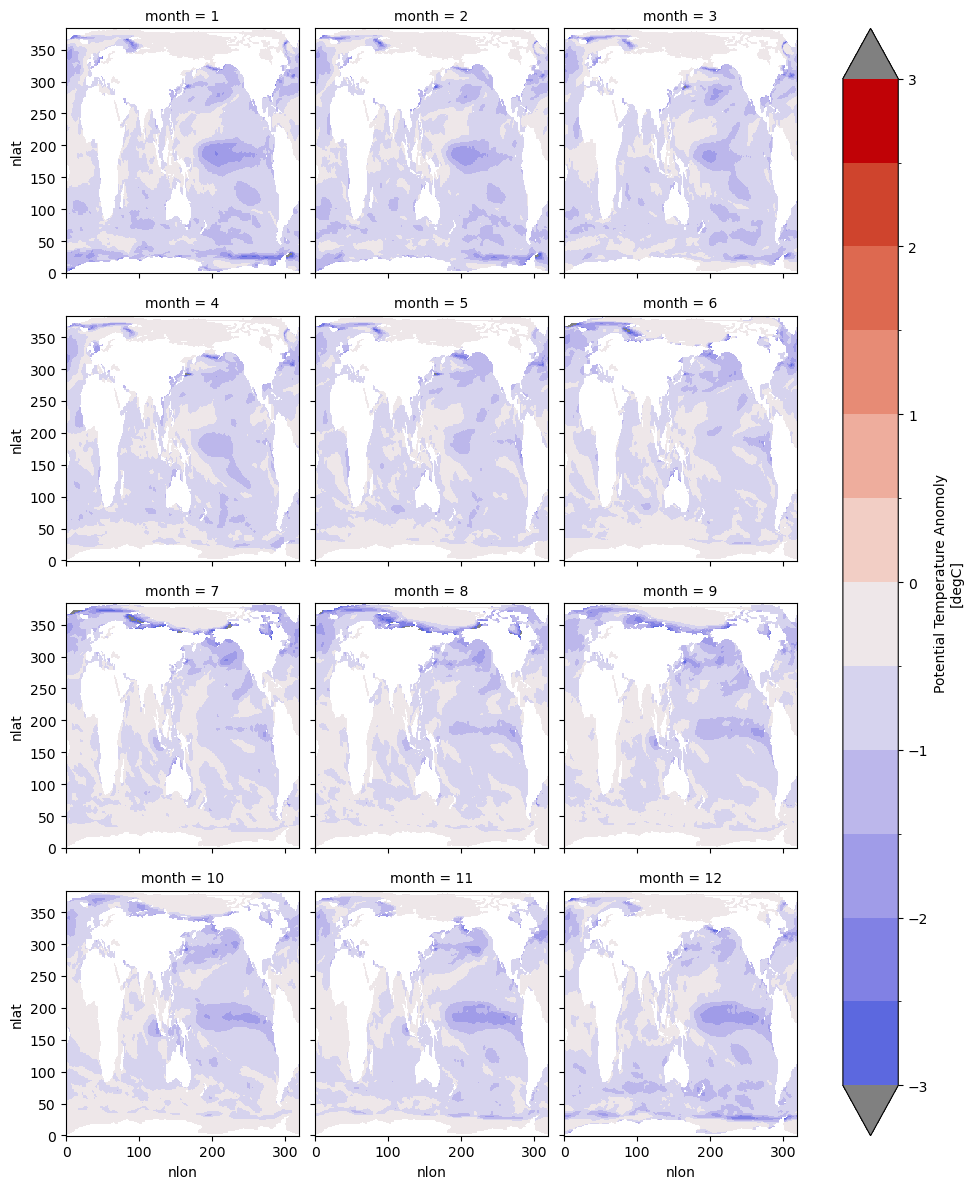

In [ ]:
# Intensity of Marine Coldwaves

ds_intensity['MCW_INTENSITY'].plot(col='month',col_wrap=3, cmap=cmap_div, levels=np.arange(-3, 3.5, .5), cbar_kwargs={'extend':'both'})